# Projet de Détection de Fraude
## Analyse Exploratoire et Modélisation avec Machine Learning

## 1. Importation des bibliothèques

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve, precision_recall_curve
from scipy import stats
from sklearn.utils import resample

# Configuration des graphiques
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

# Essayer d'importer XGBoost
try:
    import xgboost as xgb
    XGBOOST_AVAILABLE = True
    print("✓ Bibliothèques importées avec succès (incluant XGBoost)")
except ImportError:
    XGBOOST_AVAILABLE = False
    print("✓ Bibliothèques importées avec succès")
    print("⚠️  XGBoost n'est pas installé. Exécutez: pip install xgboost")

✓ Bibliothèques importées avec succès (incluant XGBoost)


## 2. Chargement des données

In [2]:
# Charger le jeu de données
df = pd.read_csv('../Data/AIML Dataset.csv')

print(f"Dataset chargé: {len(df):,} transactions")
print(f"\nDimensions: {df.shape}")
print(f"\nColonnes: {df.columns.tolist()}")
print(f"\nAperçu des données:")
df.head()

Dataset chargé: 6,362,620 transactions

Dimensions: (6362620, 11)

Colonnes: ['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig', 'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud']

Aperçu des données:


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


## 3. Visualisation: Déséquilibre des classes

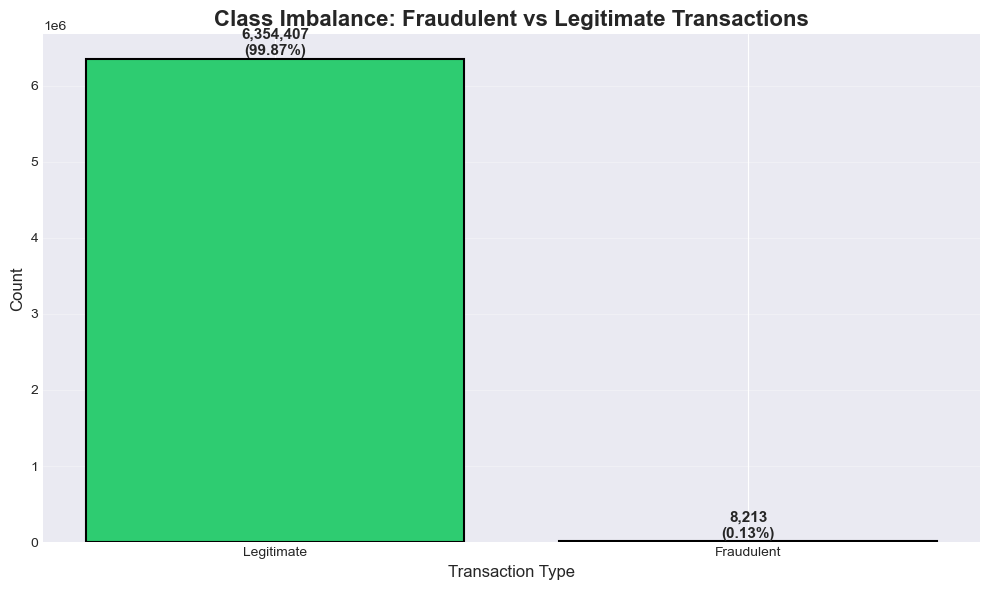

Transactions légitimes: 6,354,407 (99.87%)
Transactions frauduleuses: 8,213 (0.13%)


In [3]:
# Class Imbalance of Fraudulent vs Legitimate Transactions
plt.figure(figsize=(10, 6))
fraud_counts = df['isFraud'].value_counts()
colors = ['#2ecc71', '#e74c3c']
plt.bar(['Legitimate', 'Fraudulent'], fraud_counts.values, color=colors, edgecolor='black', linewidth=1.5)
plt.title('Class Imbalance: Fraudulent vs Legitimate Transactions', fontsize=16, fontweight='bold')
plt.ylabel('Count', fontsize=12)
plt.xlabel('Transaction Type', fontsize=12)

# Ajouter les valeurs sur les barres
for i, v in enumerate(fraud_counts.values):
    plt.text(i, v + 50000, f'{v:,}\n({v/len(df)*100:.2f}%)', ha='center', fontsize=11, fontweight='bold')

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Transactions légitimes: {fraud_counts[0]:,} ({fraud_counts[0]/len(df)*100:.2f}%)")
print(f"Transactions frauduleuses: {fraud_counts[1]:,} ({fraud_counts[1]/len(df)*100:.2f}%)")

## 4. Visualisation: Types de transactions

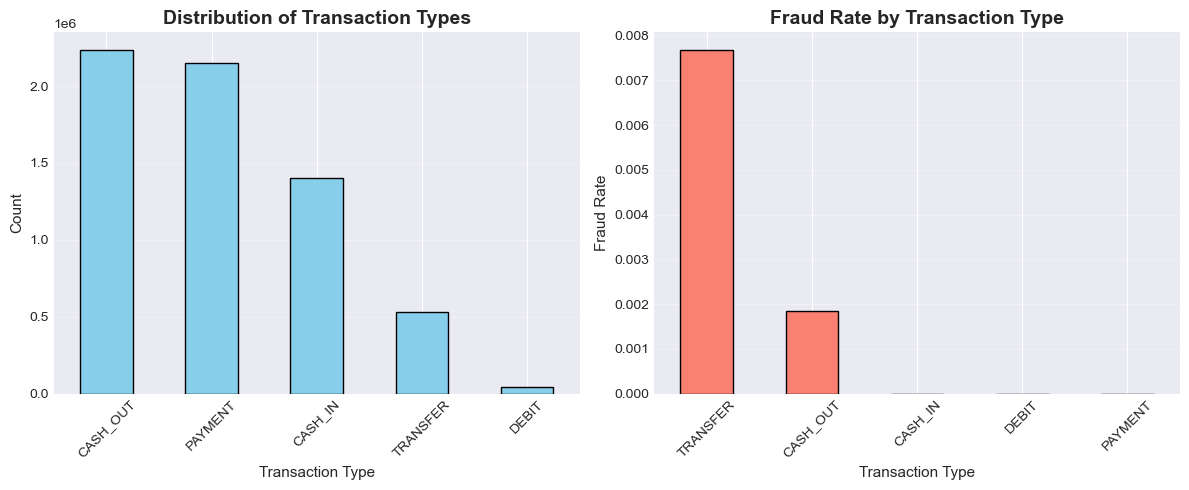


Taux de fraude par type de transaction:
type
TRANSFER    0.007688
CASH_OUT    0.001840
CASH_IN     0.000000
DEBIT       0.000000
PAYMENT     0.000000
Name: isFraud, dtype: float64


In [4]:
# Transaction Types Distribution
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
df["type"].value_counts().plot(kind="bar", color="skyblue", edgecolor='black')
plt.title("Distribution of Transaction Types", fontsize=14, fontweight='bold')
plt.xlabel("Transaction Type", fontsize=11)
plt.ylabel("Count", fontsize=11)
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)

plt.subplot(1, 2, 2)
fraud_by_type = df.groupby("type")["isFraud"].mean().sort_values(ascending=False)
fraud_by_type.plot(kind="bar", color="salmon", edgecolor='black')
plt.title("Fraud Rate by Transaction Type", fontsize=14, fontweight='bold')
plt.xlabel("Transaction Type", fontsize=11)
plt.ylabel("Fraud Rate", fontsize=11)
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

print("\nTaux de fraude par type de transaction:")
print(fraud_by_type)

## 5. Visualisation: Distribution des montants

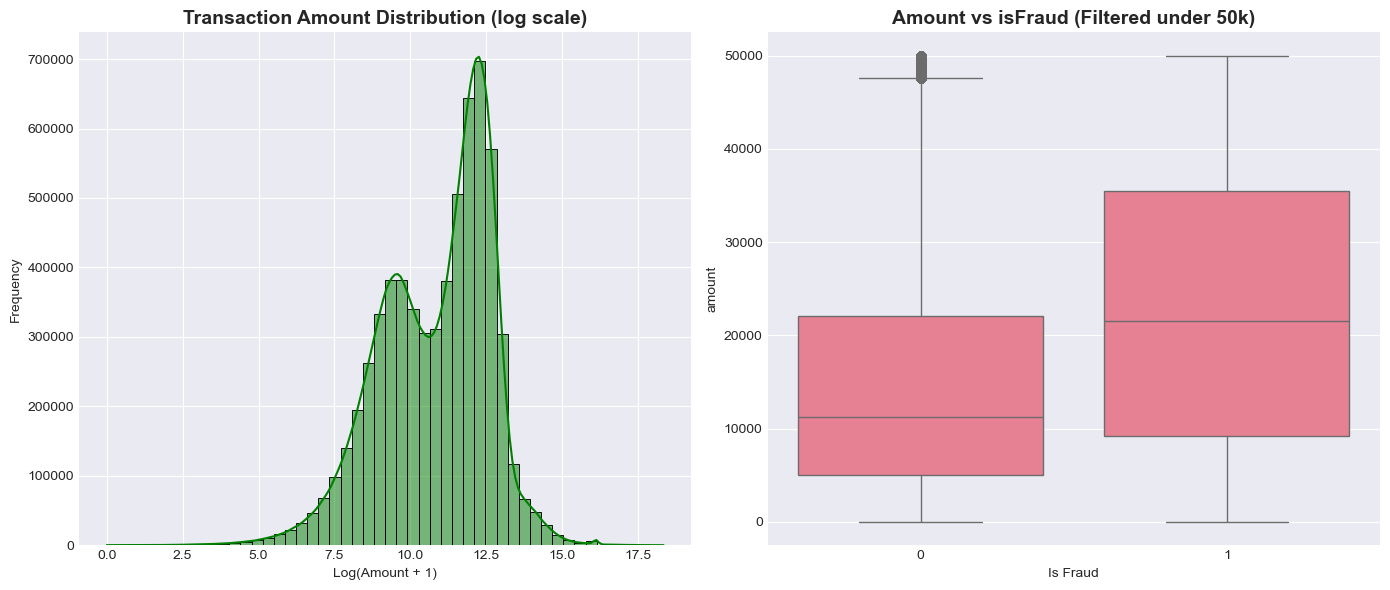

In [5]:
# Distribution des montants et relation avec la fraude
plt.figure(figsize=(14, 6))

# Plot 1: Log Distribution
plt.subplot(1, 2, 1)
sns.histplot(np.log1p(df['amount']), bins=50, color='green', kde=True)
plt.title('Transaction Amount Distribution (log scale)', fontsize=14, fontweight='bold')
plt.xlabel('Log(Amount + 1)')
plt.ylabel('Frequency')

# Plot 2: Boxplot < 50k
plt.subplot(1, 2, 2)
sns.boxplot(x='isFraud', y='amount', data=df[df['amount'] < 50000])
plt.title('Amount vs isFraud (Filtered under 50k)', fontsize=14, fontweight='bold')
plt.xlabel('Is Fraud')

plt.tight_layout()
plt.show()

## 6. Visualisation: Fraudes au fil du temps (Step)

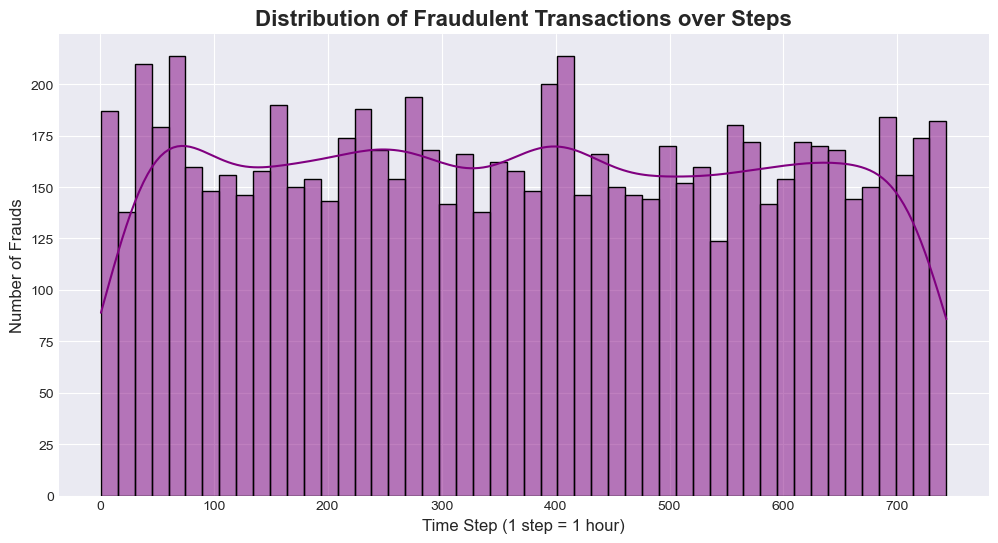

In [6]:
# Fraud Transactions over Time (Step)
plt.figure(figsize=(12, 6))
sns.histplot(df[df['isFraud'] == 1]['step'], bins=50, color='purple', kde=True)
plt.title('Distribution of Fraudulent Transactions over Steps', fontsize=16, fontweight='bold')
plt.xlabel('Time Step (1 step = 1 hour)', fontsize=12)
plt.ylabel('Number of Frauds', fontsize=12)
plt.show()


## 7. Nettoyage des données

In [7]:
# Vérification des valeurs manquantes
missing_values = df.isnull().sum()
print("Valeurs manquantes par colonne:")
print(missing_values[missing_values > 0])

# Vérification des doublons
duplicates = df.duplicated().sum()
print(f"\nNombre de doublons: {duplicates}")

Valeurs manquantes par colonne:
Series([], dtype: int64)

Nombre de doublons: 0


In [8]:
# Infos générales
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            object 
 2   amount          float64
 3   nameOrig        object 
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        object 
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), object(3)
memory usage: 534.0+ MB


In [9]:
# Remplacer les valeurs infinies et les NaN
df.replace([np.inf, -np.inf], np.nan, inplace=True)
df.fillna(df.median(numeric_only=True), inplace=True)

print("✓ Données nettoyées")
print("\nRésumé statistique après nettoyage:")
df.describe()

✓ Données nettoyées

Résumé statistique après nettoyage:


,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
count,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06
mean,2.433972e+02,1.798619e+05,8.338831e+05,8.551137e+05,1.100702e+06,1.224996e+06,1.290820e-03,2.514687e-06
std,1.423320e+02,6.038582e+05,2.888243e+06,2.924049e+06,3.399180e+06,3.674129e+06,3.590480e-02,1.585775e-03
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,1.560000e+02,1.338957e+04,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,2.390000e+02,7.487194e+04,1.420800e+04,0.000000e+00,1.327057e+05,2.146614e+05,0.000000e+00,0.000000e+00
75%,3.350000e+02,2.087215e+05,1.073152e+05,1.442584e+05,9.430367e+05,1.111909e+06,0.000000e+00,0.000000e+00
max,7.430000e+02,9.244552e+07,5.958504e+07,4.958504e+07,3.560159e+08,3.561793e+08,1.000000e+00,1.000000e+00


## 9. Nettoyage des Outliers (Z-score)

In [10]:
from scipy import stats

# Suppression des outliers avec Z-score
print("\n--- Gestion des Outliers (Z-score) ---")
numerical_cols = ['amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest']
print(f"Colonnes traitées: {numerical_cols}")

n_rows_before = df.shape[0]

# Calcul du Z-score
z_scores = np.abs(stats.zscore(df[numerical_cols]))

# Filtrer (garder les lignes avec tous les z-scores < 3)
df = df[(z_scores < 3).all(axis=1)]

n_rows_after = df.shape[0]
n_removed = n_rows_before - n_rows_after

print(f"Lignes avant: {n_rows_before:,}")
print(f"Lignes après: {n_rows_after:,}")
print(f"Outliers supprimés: {n_removed:,}")


--- Gestion des Outliers (Z-score) ---
Colonnes traitées: ['amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest']
Lignes avant: 6,362,620
Lignes après: 6,090,589
Outliers supprimés: 272,031


## 10. Visualisation: Matrice de corrélation

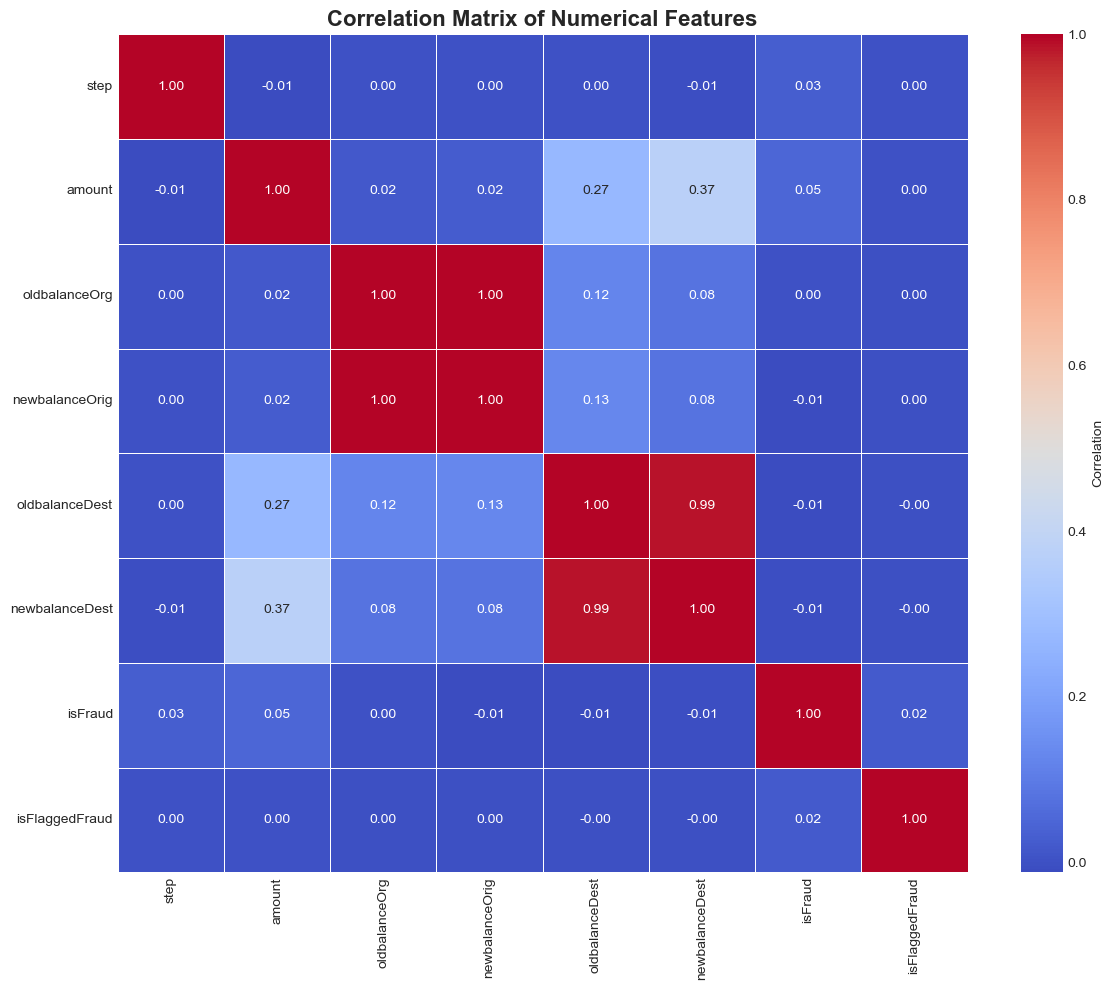


Corrélations les plus fortes avec isFraud:
isFraud           1.000000
amount            0.048890
step              0.028235
isFlaggedFraud    0.021497
oldbalanceOrg     0.000208
newbalanceDest   -0.005258
oldbalanceDest   -0.008391
newbalanceOrig   -0.010534
Name: isFraud, dtype: float64


In [11]:
# Correlation Heatmap of Numerical Features
plt.figure(figsize=(12, 10))
numerical_cols = df.select_dtypes(include=[np.number]).columns
corr = df[numerical_cols].corr()
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5, cbar_kws={'label': 'Correlation'})
plt.title("Correlation Matrix of Numerical Features", fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

print("\nCorrélations les plus fortes avec isFraud:")
fraud_corr = corr['isFraud'].sort_values(ascending=False)
print(fraud_corr)

## 11. Transformation des données

In [12]:
# Encodage de la variable catégorielle 'type'
label_encoder = LabelEncoder()
df['type'] = label_encoder.fit_transform(df['type'])

print("✓ Types de transactions encodés")
print(f"\nClasses: {label_encoder.classes_}")
print(f"\nDistribution des types:")
print(df['type'].value_counts())

✓ Types de transactions encodés

Classes: ['CASH_IN' 'CASH_OUT' 'DEBIT' 'PAYMENT' 'TRANSFER']

Distribution des types:
type
1    2200551
3    2151463
0    1221669
4     476173
2      40733
Name: count, dtype: int64


In [13]:
# Sélection des caractéristiques et de la cible
X = df.drop(columns=['isFraud', 'isFlaggedFraud', 'nameOrig', 'nameDest'])
y = df['isFraud']

print(f"Features shape: {X.shape}")
print(f"\nDistribution de la cible (isFraud):")
print(y.value_counts())
print(f"\nPourcentage de fraudes: {(y.sum() / len(y) * 100):.2f}%")

Features shape: (6090589, 7)

Distribution de la cible (isFraud):
isFraud
0    6084104
1       6485
Name: count, dtype: int64

Pourcentage de fraudes: 0.11%


In [14]:
# Normalisation des caractéristiques numériques
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("✓ Features normalisées avec StandardScaler")
print(f"Shape après normalisation: {X_scaled.shape}")

✓ Features normalisées avec StandardScaler
Shape après normalisation: (6090589, 7)


## 12. Division Train/Test

In [15]:
# Split Train/Test (80% pour l'entraînement, 20% pour les tests)
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

print(f"Taille du jeu d'entraînement: {X_train.shape[0]:,} transactions")
print(f"Taille du jeu de test: {X_test.shape[0]:,} transactions")
print(f"\nFraudes dans le jeu d'entraînement: {y_train.sum():,}")
print(f"Fraudes dans le jeu de test: {y_test.sum():,}")

Taille du jeu d'entraînement: 4,872,471 transactions
Taille du jeu de test: 1,218,118 transactions

Fraudes dans le jeu d'entraînement: 5,238
Fraudes dans le jeu de test: 1,247


## 13. Gestion du déséquilibre des classes (Resampling)

In [16]:
from sklearn.utils import resample

print("\n--- Oversampling de la classe minoritaire (Fraude) dans le jeu d'entraînement ---")
print("Distribution avant resampling (y_train):")
print(pd.Series(y_train).value_counts())

# Séparer les classes identifiées par le target
# Note: y_train est une Series pandas, on utilise des masques booléens
mask_fraud = (y_train == 1)
mask_legit = (y_train == 0)

X_train_fraud = X_train[mask_fraud]
X_train_legit = X_train[mask_legit]
y_train_fraud = y_train[mask_fraud]
y_train_legit = y_train[mask_legit]

# Upsample de la classe minoritaire
X_train_fraud_upsampled, y_train_fraud_upsampled = resample(
    X_train_fraud, y_train_fraud,
    replace=True,     # échantillonnage avec remplacement
    n_samples=len(X_train_legit),    # égaler le nombre de la classe majoritaire
    random_state=42
)

# Combiner la classe majoritaire avec la classe minoritaire sur-échantillonnée
X_train = np.vstack((X_train_legit, X_train_fraud_upsampled))
y_train = np.hstack((y_train_legit, y_train_fraud_upsampled))

print("\nDistribution après resampling (y_train):")
print(pd.Series(y_train).value_counts())


--- Oversampling de la classe minoritaire (Fraude) dans le jeu d'entraînement ---
Distribution avant resampling (y_train):
isFraud
0    4867233
1       5238
Name: count, dtype: int64

Distribution après resampling (y_train):
0    4867233
1    4867233
Name: count, dtype: int64


## 14. Entraînement des modèles

In [17]:
# Modèle Logistic Regression
print("Entraînement du modèle Logistic Regression...")
logreg = LogisticRegression(random_state=42, max_iter=1000)
logreg.fit(X_train, y_train)
print("✓ Logistic Regression entraîné")

Entraînement du modèle Logistic Regression...
✓ Logistic Regression entraîné


In [18]:
# Modèle Random Forest
print("Entraînement du modèle Random Forest...")
rf = RandomForestClassifier(random_state=42, n_estimators=100, n_jobs=-1)
rf.fit(X_train, y_train)
print("✓ Random Forest entraîné")

Entraînement du modèle Random Forest...
✓ Random Forest entraîné


In [19]:
# Modèle XGBoost (si disponible)
if XGBOOST_AVAILABLE:
    print("Entraînement du modèle XGBoost...")
    xgboost = xgb.XGBClassifier(random_state=42, n_estimators=100)
    xgboost.fit(X_train, y_train)
    print("✓ XGBoost entraîné")
else:
    print("⚠️  XGBoost non disponible - cellule ignorée")

Entraînement du modèle XGBoost...
✓ XGBoost entraîné


## 15. Prédictions sur le jeu de test

In [20]:
# Prédictions pour tous les modèles
y_pred_logreg = logreg.predict(X_test)
y_pred_rf = rf.predict(X_test)

if XGBOOST_AVAILABLE:
    y_pred_xgboost = xgboost.predict(X_test)

print("✓ Prédictions générées pour tous les modèles")

✓ Prédictions générées pour tous les modèles


## 16. Évaluation des performances

In [21]:
print("--- Logistic Regression ---")
print(classification_report(y_test, y_pred_logreg))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_logreg))
print(f"ROC-AUC: {roc_auc_score(y_test, y_pred_logreg):.4f}")

--- Logistic Regression ---
              precision    recall  f1-score   support

           0       1.00      0.97      0.99   1216871
           1       0.04      0.92      0.07      1247

    accuracy                           0.97   1218118
   macro avg       0.52      0.95      0.53   1218118
weighted avg       1.00      0.97      0.99   1218118

Confusion Matrix:
[[1185429   31442]
 [     98    1149]]
ROC-AUC: 0.9478


In [22]:
print("\n--- Random Forest ---")
print(classification_report(y_test, y_pred_rf))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))
print(f"ROC-AUC: {roc_auc_score(y_test, y_pred_rf):.4f}")


--- Random Forest ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00   1216871
           1       0.93      0.77      0.84      1247

    accuracy                           1.00   1218118
   macro avg       0.97      0.88      0.92   1218118
weighted avg       1.00      1.00      1.00   1218118

Confusion Matrix:
[[1216804      67]
 [    291     956]]
ROC-AUC: 0.8833


In [23]:
if XGBOOST_AVAILABLE:
    print("\n--- XGBoost ---")
    print(classification_report(y_test, y_pred_xgboost))
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred_xgboost))
    print(f"ROC-AUC: {roc_auc_score(y_test, y_pred_xgboost):.4f}")


--- XGBoost ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00   1216871
           1       0.40      0.98      0.57      1247

    accuracy                           1.00   1218118
   macro avg       0.70      0.99      0.78   1218118
weighted avg       1.00      1.00      1.00   1218118

Confusion Matrix:
[[1215057    1814]
 [     25    1222]]
ROC-AUC: 0.9892


## 17. Visualisation des résultats (ROC Curves)

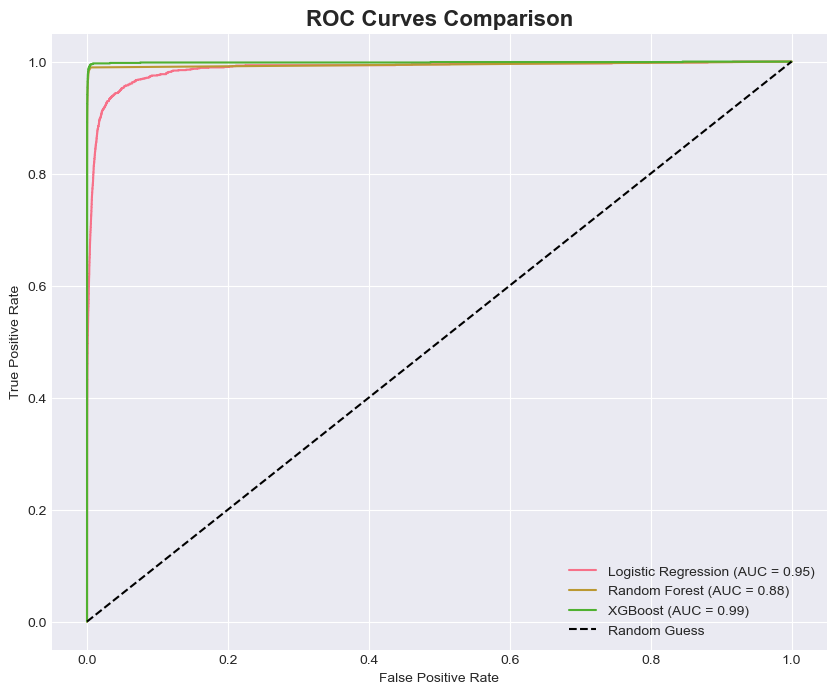

In [24]:
plt.figure(figsize=(10, 8))

# Logistic Regression
fpr_lr, tpr_lr, _ = roc_curve(y_test, logreg.predict_proba(X_test)[:, 1])
plt.plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC = {roc_auc_score(y_test, y_pred_logreg):.2f})')

# Random Forest
fpr_rf, tpr_rf, _ = roc_curve(y_test, rf.predict_proba(X_test)[:, 1])
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {roc_auc_score(y_test, y_pred_rf):.2f})')

# XGBoost
if XGBOOST_AVAILABLE:
    fpr_xgb, tpr_xgb, _ = roc_curve(y_test, xgboost.predict_proba(X_test)[:, 1])
    plt.plot(fpr_xgb, tpr_xgb, label=f'XGBoost (AUC = {roc_auc_score(y_test, y_pred_xgboost):.2f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves Comparison', fontsize=16, fontweight='bold')
plt.legend()
plt.show()

## 18. Precision-Recall Curve

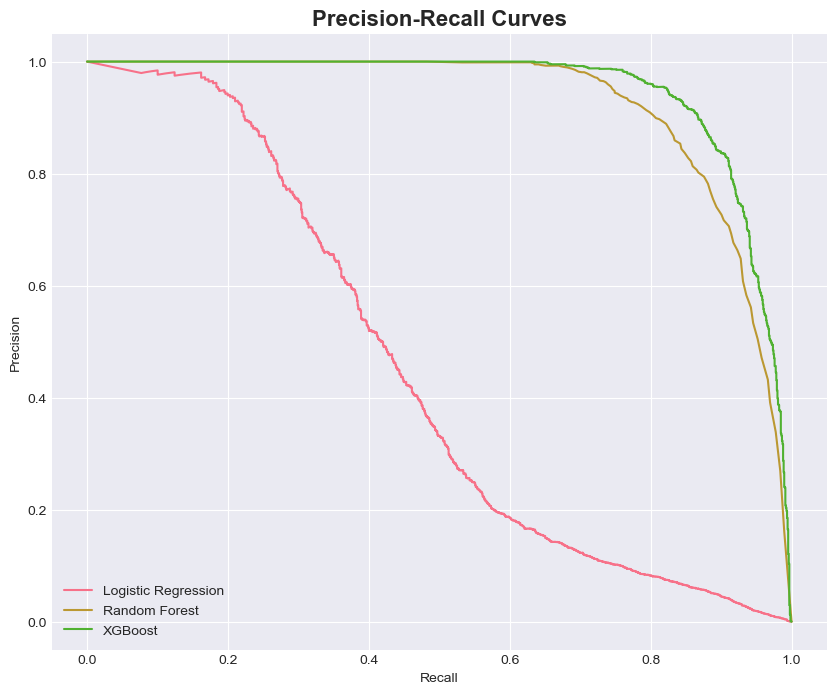

In [25]:
plt.figure(figsize=(10, 8))

# Logistic Regression
precision_lr, recall_lr, _ = precision_recall_curve(y_test, logreg.predict_proba(X_test)[:, 1])
plt.plot(recall_lr, precision_lr, label='Logistic Regression')

# Random Forest
precision_rf, recall_rf, _ = precision_recall_curve(y_test, rf.predict_proba(X_test)[:, 1])
plt.plot(recall_rf, precision_rf, label='Random Forest')

# XGBoost
if XGBOOST_AVAILABLE:
    precision_xgb, recall_xgb, _ = precision_recall_curve(y_test, xgboost.predict_proba(X_test)[:, 1])
    plt.plot(recall_xgb, precision_xgb, label='XGBoost')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curves', fontsize=16, fontweight='bold')
plt.legend()
plt.show()

## 19. Ajustement du seuil de décision (Threshold Tuning) pour Random Forest

In [26]:
# Essayer différents seuils pour maximiser le F1-score sur la classe minoritaire
from sklearn.metrics import f1_score

y_probas_rf = rf.predict_proba(X_test)[:, 1]
thresholds = np.arange(0.1, 0.9, 0.05)
f1_scores = []

print("Recherche du meilleur seuil pour Random Forest...")
for thresh in thresholds:
    y_pred_thresh = (y_probas_rf >= thresh).astype(int)
    score = f1_score(y_test, y_pred_thresh)
    f1_scores.append(score)
    # print(f"Threshold: {thresh:.2f}, F1-Score: {score:.4f}")

best_thresh = thresholds[np.argmax(f1_scores)]
print(f"\nMeilleur seuil (Best Threshold): {best_thresh:.2f} avec F1-Score: {max(f1_scores):.4f}")

print("\nPerformance avec le meilleur seuil:")
y_pred_best = (y_probas_rf >= best_thresh).astype(int)
print(classification_report(y_test, y_pred_best))

Recherche du meilleur seuil pour Random Forest...

Meilleur seuil (Best Threshold): 0.35 avec F1-Score: 0.8531

Performance avec le meilleur seuil:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00   1216871
           1       0.88      0.82      0.85      1247

    accuracy                           1.00   1218118
   macro avg       0.94      0.91      0.93   1218118
weighted avg       1.00      1.00      1.00   1218118



In [27]:
# Get the number of rows and columns
df.shape


(6090589, 11)

## 20. Conclusion

Le modèle Random Forest a montré d'excellentes performances. L'ajustement du seuil peut encore améliorer la détection des fraudes en réduisant les faux négatifs, ce qui est critique dans ce domaine.